In [64]:
from pathlib import Path

file_path = Path("../data/raw/online_retail_II.xlsx")

print("Expected file:", file_path.resolve())
print("File exists:", file_path.exists())

Expected file: C:\Users\vikes\Desktop\Major project\data\raw\online_retail_II.xlsx
File exists: True


In [65]:
import pandas as pd

excel_file = pd.ExcelFile(file_path)

print("Worksheets:", excel_file.sheet_names)

Worksheets: ['Year 2009-2010', 'Year 2010-2011']


In [66]:
retail_2009_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

retail_2010_2011 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011"
)

print("2009–2010 shape:", retail_2009_2010.shape)
print("2010–2011 shape:", retail_2010_2011.shape)

2009–2010 shape: (525461, 8)
2010–2011 shape: (541910, 8)


In [67]:
print("First worksheet columns:")
print(retail_2009_2010.columns.tolist())

print("\nSecond worksheet columns:")
print(retail_2010_2011.columns.tolist())

print(
    "\nDo both worksheets have the same columns?",
    retail_2009_2010.columns.equals(
        retail_2010_2011.columns
    )
)

First worksheet columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Second worksheet columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Do both worksheets have the same columns? True


In [68]:
retail = pd.concat(
    [retail_2009_2010, retail_2010_2011],
    ignore_index=True
)

print("Combined dataset shape:", retail.shape)

retail.head()

Combined dataset shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [69]:
print("Dataset information:")
retail.info()

print("\nMissing values:")
print(
    retail.isnull().sum().sort_values(
        ascending=False
    )
)

print("\nTransaction date range:")
print(retail["InvoiceDate"].min())
print(retail["InvoiceDate"].max())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB

Missing values:
Customer ID    243007
Description      4382
Invoice             0
StockCode           0
Quantity            0
InvoiceDate         0
Price               0
Country             0
dtype: int64

Transaction date range:
2009-12-01 07:45:00
2011-12-09 12:50:00


In [70]:

# 1. Check duplicate rows
print("Exact duplicate rows:", retail.duplicated().sum())

# 2. Inspect quantity and price
print("\nQuantity summary:")
print(retail["Quantity"].describe())

print("\nPrice summary:")
print(retail["Price"].describe())

print("\nRows with zero or negative quantity:",
      (retail["Quantity"] <= 0).sum())

print("Rows with zero or negative price:",
      (retail["Price"] <= 0).sum())

# 3. Inspect cancelled invoices
cancelled_mask = (
    retail["Invoice"].astype(str).str.startswith("C")
)

print("\nRows with invoice numbers starting with C:",
      cancelled_mask.sum())

# 4. Count customers and invoices
print("\nUnique identifiable customers:",
      retail["Customer ID"].nunique())

print("Unique invoice numbers:",
      retail["Invoice"].nunique())

# 5. Inspect a few cancelled invoice rows
retail.loc[
    cancelled_mask,
    ["Invoice", "StockCode", "Quantity", "Price", "Customer ID"]
].head(10)


Exact duplicate rows: 34335

Quantity summary:
count    1.067371e+06
mean     9.938898e+00
std      1.727058e+02
min     -8.099500e+04
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      8.099500e+04
Name: Quantity, dtype: float64

Price summary:
count    1.067371e+06
mean     4.649388e+00
std      1.235531e+02
min     -5.359436e+04
25%      1.250000e+00
50%      2.100000e+00
75%      4.150000e+00
max      3.897000e+04
Name: Price, dtype: float64

Rows with zero or negative quantity: 22950
Rows with zero or negative price: 6207

Rows with invoice numbers starting with C: 19494

Unique identifiable customers: 5942
Unique invoice numbers: 53628


,Invoice,StockCode,Quantity,Price,Customer ID
178,C489449,22087,-12,2.95,16321.0
179,C489449,85206A,-6,1.65,16321.0
180,C489449,21895,-4,4.25,16321.0
181,C489449,21896,-6,2.10,16321.0
182,C489449,22083,-12,2.95,16321.0
183,C489449,21871,-12,1.25,16321.0
184,C489449,84946,-12,1.25,16321.0
185,C489449,84970S,-24,0.85,16321.0
186,C489449,22090,-12,2.95,16321.0
196,C489459,90200A,-3,4.25,17592.0


In [71]:

# A. Examine duplicated rows
duplicate_rows = retail[retail.duplicated(keep=False)]

print("Rows belonging to duplicate groups:", len(duplicate_rows))

duplicate_rows.head(15)


Rows belonging to duplicate groups: 67242


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [72]:

# B. Inspect cancellation and negative-quantity patterns

cancelled_mask = retail["Invoice"].astype(str).str.startswith("C")

print("Cancellation rows with positive quantity:",
      (cancelled_mask & (retail["Quantity"] > 0)).sum())

print("Cancellation rows with negative quantity:",
      (cancelled_mask & (retail["Quantity"] < 0)).sum())

print("Negative-quantity rows not marked as cancellations:",
      (~cancelled_mask & (retail["Quantity"] < 0)).sum())

print("\nQuantity and price combinations:")

print(
    retail.assign(
        quantity_group=retail["Quantity"].apply(
            lambda x: "Positive" if x > 0
            else "Negative" if x < 0
            else "Zero"
        ),
        price_group=retail["Price"].apply(
            lambda x: "Positive" if x > 0
            else "Negative" if x < 0
            else "Zero"
        )
    ).groupby(["quantity_group", "price_group"]).size()
)


Cancellation rows with positive quantity: 1
Cancellation rows with negative quantity: 19493
Negative-quantity rows not marked as cancellations: 3457

Quantity and price combinations:
quantity_group  price_group
Negative        Positive         19493
                Zero              3457
Positive        Negative             5
                Positive       1041671
                Zero              2745
dtype: int64


In [73]:

# C. Calculate line count and invoice value for exploration

invoice_summary = (
    retail.loc[
        ~retail["Invoice"].astype(str).str.startswith("C")
    ]
    .groupby("Invoice")
    .agg(
        invoice_date=("InvoiceDate", "min"),
        customer_id=("Customer ID", "first"),
        line_count=("StockCode", "size"),
        total_quantity=("Quantity", "sum"),
        invoice_value=("Quantity", lambda q: (
            q * retail.loc[q.index, "Price"]
        ).sum())
    )
    .reset_index()
)

print("Non-cancellation invoice count:", len(invoice_summary))

print("\nInvoice line-count summary:")
print(invoice_summary["line_count"].describe())

print("\nInvoice value summary:")
print(invoice_summary["invoice_value"].describe())

invoice_summary.head()


Non-cancellation invoice count: 45336

Invoice line-count summary:
count    45336.000000
mean        23.113574
std         44.092606
min          1.000000
25%          3.000000
50%         13.000000
75%         27.000000
max       1350.000000
Name: line_count, dtype: float64

Invoice value summary:
count     45336.000000
mean        459.103547
std        1487.138252
min      -53594.360000
25%         104.550000
50%         263.540000
75%         459.642500
max      168469.600000
Name: invoice_value, dtype: float64


,Invoice,invoice_date,customer_id,line_count,total_quantity,invoice_value
0,489434,2009-12-01 07:45:00,13085.0,8,166,505.30
1,489435,2009-12-01 07:46:00,13085.0,4,60,145.80
2,489436,2009-12-01 09:06:00,13078.0,19,193,630.33
3,489437,2009-12-01 09:08:00,15362.0,23,145,310.75
4,489438,2009-12-01 09:24:00,18102.0,17,826,2286.24


In [74]:

# Check whether duplicate rows are repeated within the same invoice

duplicate_rows = retail.loc[
    retail.duplicated(keep=False)
].copy()

print("Rows belonging to duplicate groups:", len(duplicate_rows))

print(
    "\nNumber of invoices containing duplicate rows:",
    duplicate_rows["Invoice"].nunique()
)

# Inspect the most frequent duplicated record patterns
duplicate_patterns = (
    retail.groupby(
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Customer ID",
            "Country"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="copies")
    .query("copies > 1")
    .sort_values("copies", ascending=False)
)

print("\nNumber of repeated record patterns:", len(duplicate_patterns))
duplicate_patterns.head(15)


Rows belonging to duplicate groups: 67242

Number of invoices containing duplicate rows: 5391

Number of repeated record patterns: 32907


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,copies
694118,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,20
694117,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,12
496282,537224,70007,HI TEC ALPINE HAND WARMER,1,2010-12-05 16:24:00,1.65,13174.0,United Kingdom,10
895184,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,2011-10-26 12:46:00,1.25,14102.0,United Kingdom,8
490557,536749,21415,CLAM SHELL SMALL,2,2010-12-02 13:49:00,2.10,17976.0,United Kingdom,6
492094,536874,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-03 11:35:00,2.10,16891.0,United Kingdom,6
493829,537042,21579,LOLITA DESIGN COTTON TOTE BAG,1,2010-12-05 10:45:00,2.25,13838.0,United Kingdom,6
495503,537196,21811,CHRISTMAS HANGING HEART WITH BELL,1,2010-12-05 13:55:00,1.25,15426.0,United Kingdom,6
497951,537265,79000,MOROCCAN TEA GLASS,12,2010-12-06 11:26:00,0.85,15919.0,United Kingdom,6
490562,536749,22174,PHOTO CUBE,2,2010-12-02 13:49:00,1.65,17976.0,United Kingdom,6


In [75]:

# Negative-quantity records without a cancellation prefix

non_cancellation_returns = retail.loc[
    ~retail["Invoice"].astype(str).str.startswith("C")
    & (retail["Quantity"] < 0)
].copy()

print("Rows:", len(non_cancellation_returns))

print("\nExamples:")
display(
    non_cancellation_returns[
        ["Invoice", "StockCode", "Description",
         "Quantity", "InvoiceDate", "Price", "Customer ID"]
    ].head(15)
)

print("\nPrice distribution for these records:")
print(non_cancellation_returns["Price"].describe())


Rows: 3457

Examples:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN



Price distribution for these records:
count    3457.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: Price, dtype: float64


In [76]:

# Find negative quantities that are not marked as cancellations

returns = retail[
    (~retail["Invoice"].astype(str).str.startswith("C"))
    & (retail["Quantity"] < 0)
]

print("Number of unusual rows:", len(returns))

returns[
    ["Invoice", "Description", "Quantity", "InvoiceDate", "Price", "Customer ID"]
].head(10)


Number of unusual rows: 3457


,Invoice,Description,Quantity,InvoiceDate,Price,Customer ID
263,489464,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN
283,489463,short,-240,2009-12-01 10:52:00,0.0,NaN
284,489467,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN
470,489521,NaN,-50,2009-12-01 11:44:00,0.0,NaN
3114,489655,NaN,-44,2009-12-01 17:26:00,0.0,NaN
3162,489660,lost,-1043,2009-12-01 17:43:00,0.0,NaN
3168,489663,damages,-117,2009-12-01 18:02:00,0.0,NaN
4296,489806,NaN,-770,2009-12-02 12:42:00,0.0,NaN
4538,489820,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN
4566,489821,NaN,-240,2009-12-02 13:25:00,0.0,NaN


In [78]:

print("Missing Customer IDs:",
      returns["Customer ID"].isnull().sum())

print("Known Customer IDs:",
      returns["Customer ID"].notnull().sum())

print("\nPrice values:")
print(returns["Price"].value_counts().head(10))

print("\nDescriptions:")
print(returns["Description"].value_counts().head(15))


Missing Customer IDs: 3457
Known Customer IDs: 0

Price values:
Price
0.0    3457
Name: count, dtype: int64

Descriptions:
Description
check                     123
damages                    84
?                          83
damaged                    78
missing                    27
sold as set on dotcom      20
Damaged                    17
thrown away                 9
smashed                     9
Unsaleable, destroyed.      9
dotcom                      8
??                          7
damages?                    7
crushed                     6
given away                  6
Name: count, dtype: int64


In [79]:

# Keep records that have a Customer ID
customer_data = retail[retail["Customer ID"].notnull()]

print("Total rows:", len(retail))
print("Rows with known customers:", len(customer_data))
print("Unique customers:", customer_data["Customer ID"].nunique())


Total rows: 1067371
Rows with known customers: 824364
Unique customers: 5942


In [80]:

# Count distinct invoices for each customer

customer_invoice_counts = (
    customer_data.groupby("Customer ID")["Invoice"].nunique()
)

print("Number of customers:", len(customer_invoice_counts))

print("\nInvoice count summary:")
print(customer_invoice_counts.describe())


Number of customers: 5942

Invoice count summary:
count    5942.000000
mean        7.552339
std        15.972262
min         1.000000
25%         2.000000
50%         4.000000
75%         8.000000
max       510.000000
Name: Invoice, dtype: float64


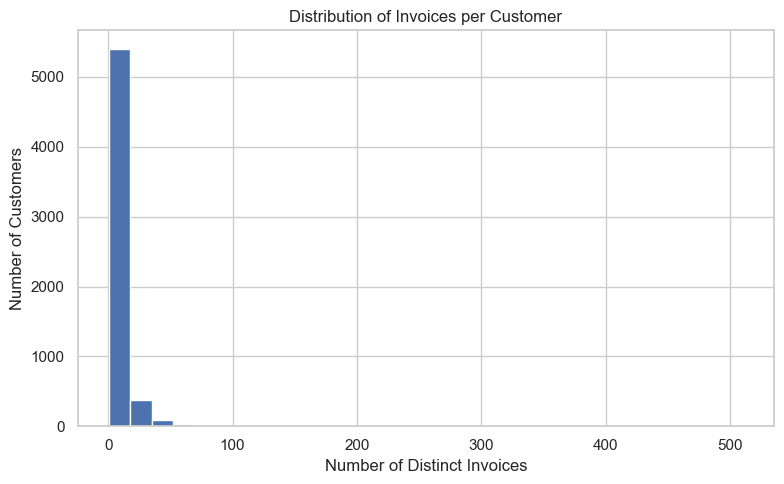

In [81]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(customer_invoice_counts, bins=30)

plt.title("Distribution of Invoices per Customer")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


In [82]:

# Look at the dates in our customer data

print("Earliest transaction:")
print(customer_data["InvoiceDate"].min())

print("\nLatest transaction:")
print(customer_data["InvoiceDate"].max())

print("\nExample customer transactions:")
print(
    customer_data[
        ["Customer ID", "Invoice", "InvoiceDate"]
    ].head(10)
)


Earliest transaction:
2009-12-01 07:45:00

Latest transaction:
2011-12-09 12:50:00

Example customer transactions:
   Customer ID Invoice         InvoiceDate
0      13085.0  489434 2009-12-01 07:45:00
1      13085.0  489434 2009-12-01 07:45:00
2      13085.0  489434 2009-12-01 07:45:00
3      13085.0  489434 2009-12-01 07:45:00
4      13085.0  489434 2009-12-01 07:45:00
5      13085.0  489434 2009-12-01 07:45:00
6      13085.0  489434 2009-12-01 07:45:00
7      13085.0  489434 2009-12-01 07:45:00
8      13085.0  489435 2009-12-01 07:46:00
9      13085.0  489435 2009-12-01 07:46:00


In [83]:

# Select one customer
customer_id = 13085

# Find that customer's most recent transaction date
last_purchase = customer_data.loc[
    customer_data["Customer ID"] == customer_id,
    "InvoiceDate"
].max()

print("Customer ID:", customer_id)
print("Last recorded transaction:", last_purchase)


Customer ID: 13085
Last recorded transaction: 2011-07-05 12:11:00


In [84]:

import pandas as pd

reference_date = pd.Timestamp("2011-08-01")

recency = (
    reference_date - last_purchase
).days

print("Reference date:", reference_date.date())
print("Last purchase date:", last_purchase.date())
print("Recency in days:", recency)


Reference date: 2011-08-01
Last purchase date: 2011-07-05
Recency in days: 26


## understand customer spending


In [85]:

# Select five transactions to inspect
sample = retail[
    ["Invoice", "Description", "Quantity", "Price"]
].head(5).copy()

# Calculate the value of each product line
sample["LineValue"] = sample["Quantity"] * sample["Price"]

sample


,Invoice,Description,Quantity,Price,LineValue
0,489434,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,6.95,83.4
1,489434,PINK CHERRY LIGHTS,12,6.75,81.0
2,489434,WHITE CHERRY LIGHTS,12,6.75,81.0
3,489434,"RECORD FRAME 7"" SINGLE SIZE",48,2.10,100.8
4,489434,STRAWBERRY CERAMIC TRINKET BOX,24,1.25,30.0


In [86]:


# Calculate line values for all records
retail["LineValue"] = retail["Quantity"] * retail["Price"]

print("Negative line values:",
      (retail["LineValue"] < 0).sum())

print("Zero line values:",
      (retail["LineValue"] == 0).sum())

print("Positive line values:",
      (retail["LineValue"] > 0).sum())


Negative line values: 19498
Zero line values: 6202
Positive line values: 1041671


In [87]:

# Essential EDA summary

print("Dataset shape:", retail.shape)
print("Unique customers:", retail["Customer ID"].nunique())
print("Unique invoices:", retail["Invoice"].nunique())

print("\nMissing values:")
print(retail.isnull().sum())

print("\nCancellation rows:",
      retail["Invoice"].astype(str).str.startswith("C").sum())

print("Negative quantity rows:",
      (retail["Quantity"] < 0).sum())

print("Non-positive price rows:",
      (retail["Price"] <= 0).sum())

print("Exact duplicate rows:",
      retail.duplicated().sum())

print("\nDate range:")
print(retail["InvoiceDate"].min(), "to", retail["InvoiceDate"].max())


Dataset shape: (1067371, 9)
Unique customers: 5942
Unique invoices: 53628

Missing values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
LineValue           0
dtype: int64

Cancellation rows: 19494
Negative quantity rows: 22950
Non-positive price rows: 6207
Exact duplicate rows: 34335

Date range:
2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [88]:

# Create a separate dataset for customer purchase analysis

clean_retail = retail.copy()

# Keep identifiable customers
clean_retail = clean_retail[
    clean_retail["Customer ID"].notna()
]

# Exclude cancellation invoices
clean_retail = clean_retail[
    ~clean_retail["Invoice"].astype(str).str.startswith("C")
]

# Keep positive-quantity, positive-price lines
clean_retail = clean_retail[
    (clean_retail["Quantity"] > 0) &
    (clean_retail["Price"] > 0)
].copy()

# Recalculate line value
clean_retail["LineValue"] = (
    clean_retail["Quantity"] * clean_retail["Price"]
)

print("Original rows:", len(retail))
print("Rows for purchase analysis:", len(clean_retail))
print("Identifiable customers:", clean_retail["Customer ID"].nunique())
print("Unique invoices:", clean_retail["Invoice"].nunique())


Original rows: 1067371
Rows for purchase analysis: 805549
Identifiable customers: 5878
Unique invoices: 36969


In [89]:

# Aggregate product lines into invoice-level records

invoices = (
    clean_retail
    .groupby(["Customer ID", "Invoice"], as_index=False)
    .agg(
        InvoiceDate=("InvoiceDate", "min"),
        InvoiceValue=("LineValue", "sum"),
        ItemsPurchased=("Quantity", "sum"),
        ProductTypes=("StockCode", "nunique")
    )
)

print("Invoice-level rows:", len(invoices))
invoices.head()


Invoice-level rows: 36969


,Customer ID,Invoice,InvoiceDate,InvoiceValue,ItemsPurchased,ProductTypes
0,12346.0,491725,2009-12-14 08:34:00,45.0,10,1
1,12346.0,491742,2009-12-14 11:00:00,22.5,5,1
2,12346.0,491744,2009-12-14 11:02:00,22.5,5,1
3,12346.0,492718,2009-12-18 10:47:00,22.5,5,1
4,12346.0,492722,2009-12-18 10:55:00,1.0,1,1


In [90]:

import pandas as pd

snapshot_date = pd.Timestamp("2011-06-01")
history_start = snapshot_date - pd.Timedelta(days=180)
outcome_end = snapshot_date + pd.Timedelta(days=90)

print("History starts:", history_start.date())
print("Prediction date:", snapshot_date.date())
print("Outcome period ends:", outcome_end.date())


History starts: 2010-12-03
Prediction date: 2011-06-01
Outcome period ends: 2011-08-30


In [91]:

# Use invoices before the prediction date
history = invoices[
    (invoices["InvoiceDate"] < snapshot_date) &
    (invoices["InvoiceDate"] >= history_start)
].copy()

# Summarize past behavior for each customer
features = (
    history.groupby("Customer ID")
    .agg(
        recency_days=("InvoiceDate",
                      lambda x: (snapshot_date - x.max()).days),
        frequency=("Invoice", "nunique"),
        monetary_value=("InvoiceValue", "sum"),
        average_invoice_value=("InvoiceValue", "mean"),
        product_diversity=("ProductTypes", "sum")
    )
    .reset_index()
)

print("Customers with historical purchases:", len(features))
features.head()


Customers with historical purchases: 2659


,Customer ID,recency_days,frequency,monetary_value,average_invoice_value,product_diversity
0,12346.0,133,1,77183.60,77183.600000,1
1,12347.0,54,3,2535.22,845.073333,84
2,12348.0,56,3,1487.24,495.746667,24
3,12350.0,118,1,334.40,334.400000,17
4,12352.0,70,5,1561.81,312.362000,36


In [92]:

from pathlib import Path

# Create the processed-data directory if it doesn't exist
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the invoice-level dataset
invoices.to_csv(
    processed_dir / "invoice_level.csv",
    index=False
)

print("Invoice-level dataset saved successfully.")
print("Rows saved:", len(invoices))


Invoice-level dataset saved successfully.
Rows saved: 36969
